# Notebook for photometric calibration of OmegaCAM frames

It receives as input a coadded frame output from Swarp and does the following:

* Read coordinates from FITS CRVAL1 and CRVAL2 keywords
* Query  skymapper catalogue for sources within 0.7 degrees
* Aperture photometry on these sources
* Determination of zero points
* Write data calibarted in physical units 10**(-15) erg/s/cm**2/arcsec**2
* Write headers with information to interpret file
* Write some check tables and plots

This is the last of the data reduction steps of the mefpp suite. Data analysis should easily follow from these calibrated frames.


In [1]:
# system utilities
import os
import glob
import copy
from textwrap import wrap

# to logg messages and debug
import logging

logging.basicConfig(
#    filename="test.log",
    level=logging.INFO,
    format="%(asctime)s:%(levelname)s:%(message)s"
    )

# modules to query skymapper 
import urllib.request

# plotting module
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import cm
from matplotlib.colors import LogNorm

# numeric and table data modules
import numpy as np
from numpy import errstate,isneginf,array
from scipy.optimize import fsolve

# dataframes module
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# module to read Fits files
from astropy.io import fits

# image visualization and World Coordinate System modules
from astropy.visualization import simple_norm
from astropy.wcs import WCS

# units and coordinate handling
from astropy import units as u
from astropy.time import Time
from astropy.coordinates import SkyCoord, get_moon, EarthLocation, AltAz
from astropy.stats import sigma_clipped_stats

# Moon quantities
import astroplan

# Apperture photometry module
from photutils import SkyCircularAperture, aperture_photometry, SkyCircularAnnulus

# here we import the local mefpp_run library
import sys
sys.path.insert(0,'/home/fselman/omegacam/mefpp/python')
from mefpp_zp import *
sys.path


['/home/fselman/omegacam/mefpp/python',
 '/opt/pampelmuse_0.100.11.2',
 '/home/fselman/omegacam/mefpp/python',
 '/opt/anaconda3/lib/python36.zip',
 '/opt/anaconda3/lib/python3.6',
 '/opt/anaconda3/lib/python3.6/lib-dynload',
 '',
 '/opt/anaconda3/lib/python3.6/site-packages',
 '/opt/anaconda3/lib/python3.6/site-packages/IPython/extensions',
 '/home/fselman/.ipython']

In [ ]:
def getKeyListVal(filename, keys):
    keys_dict = {}
    with fits.open(filename) as hdu_list:
        primary_header = hdu_list[0].header
        for key in keys:
            keys_dict[key] = primary_header[key]
        return keys_dict


# Only skymapper defined and only for r_SDSS and NB_659
# but it should be easily extensible
#
class ZPCalibration:    
    """A class to contain a pandas dataframe with the data
    to calibrate frame and the zero points needed for the calibration."""
    def __init__(self, frame, calibrator, mlim, mag_min, mag_max, dmag_filter, ap_radius, ap_sky_r1, ap_sky_r2):
        self.frame = frame

        self.basedir = os.path.dirname(frame)
        logging.info('ZPCalibration: basedir: %s'%self.basedir)
        
        # open image and read
        logging.info('ZPCalibration: init: reading frame')
        self.data, self.hdu = fits.getdata(self.frame, header=True)
        #print(self.hdu.tostring(sep='\n'))
        
        # get wcs
        logging.info('ZPCalibration: init: loading wcs info from frame')
        self.wcs = WCS(self.frame)
        
        # plate scale
        cdi_j = np.array(list(getKeyListVal(self.frame, ['CD1_1', 'CD1_2', 'CD2_1', 'CD2_2']).values()))
        self.sx = np.sqrt(cdi_j[0]**2+cdi_j[1]**2)*3600.0
        self.sy = np.sqrt(cdi_j[2]**2+cdi_j[3]**2)*3600.0
        self.plate_scale = (self.sx+self.sy)/2.0 # plate scale in arcseconds
        logging.info('ZPCalibration: plate_scale: %6.3f (sx: %6.3f - sy: %6.3f) arcsec/pix'%(self.plate_scale, self.sx, self.sy))

        
        # get average gain from first frame used by Swarp
        self.avg_gain = self.getAvgGainFromFrame()

        # some variables not yet determined
        self.aperture = None
        self.convFactor_ADU_Flambda = None
        
        ## orig sky level pos
        self.orig_exptime = self.getAvgExpTimeFromFrames()
        self.avg_exptime = np.mean(list(self.orig_exptime.values())) # we keep visible list nature
        # orig sky level pos
        
        # information needed to do the photometric calibration
        #
        self.calibrator = calibrator # Name of calibrator, for now only skymapper
        self.mlim = mlim # faintest magnitude to download from catalogue
        self.mag_min =  mag_min # brightest magnitude to do calibartipn
        self.mag_max = mag_max # fainter magnitude to do calibration
        self.dmag_filter = dmag_filter # width around magnitude line to do sigma clipping
        
        # we get observing passband from headers
        #
        self.band = getKeyListVal(frame, ['FILTER'])['FILTER'].strip() 
        
        # coordinates of the center of the field
        self.crval1 = float(getKeyListVal(frame, ['CRVAL1'])['CRVAL1'])
        self.crval2 = float(getKeyListVal(frame, ['CRVAL2'])['CRVAL2'])

        # we load the df with the calibrator data
        # we need positions and magnitudes
        #
        if calibrator == 'skymapper':
            self.df = self.getSkyMapperDf()
        else:
            self.df = None
            
        # Now we load the dataframe with the raw magnitudes in band self.band
        # Note that self.band will be the name of the column of the data frame
        
        # we add the raw magnitudes to self.df
        self.ap_radius = ap_radius
        self.sky_annulus_r1 = ap_sky_r1
        self.sky_annulus_r2 = ap_sky_r2
        self.doPhot() # first run to get raw magnitudes and convertion factors
        
        # here we get the zero points:
        #    zp: to go from ADUs in orig files to magnitudes
        #  zphc: to go from e/s to std magnitudes. To compare with Health Check values.
        #   zp2: to go from Flambda (in erg/s/cm**2/Angstrom) to std magnitudes
        # magzp: to go from DNs (in erg/s/cm**2 to std magnitudes)
        #
        self.zp, self.slope, self.sigma = self.getZP()
        logging.info('ZPCalibration: zp: {0} to go from ADUs in orig files to mags'.format(self.zp))
        
        self.zphc = self.zp+2.5*np.log10(self.avg_gain/self.avg_exptime) # correct gain from ADU to e/s
        logging.info('ZPCalibration: zphc: {0} to go from e/s to std mags.'.format(self.zphc))
        
        self.zp2 = self.getPhysicalUnitsZP()
        logging.info('ZPCalibration: zp2: {0} to go from Flambda to std mags'.format(self.zp2))
  
        self.filterWidth = self.getFilterWidth(self.band)
        self.filterPivotWavelength = self.getPivotWavelength(self.band)
        self.magzp = self.zp2 + \
                    2.5*np.log10(self.filterWidth) + \
                    2.5*np.log10(10**(15)) + \
                    2.5*np.log10(1.0/self.plate_scale**2) # DN in 10**(-15)erg/s/cm**2/asec**2
        logging.info('ZPCalibration: magzp: {0} (from DN to AB mags)'.format(self.magzp))
        
        # We get the conversion factor to Flambda in erg/s/cm^2/Angstrom
        # Imaging data should provide physical units of erg/s/cm^2/arcsec^2
        # We multiply by 10**15 to have numbers closer to 1 for usual objects
        # Note that the magzp was adjusted similarly
        #
        self.convFactor_ADU_Flambda = 10**((self.zp2 - self.zp)/2.5)                
        self.convFactor_ADU_DN = 10**(15)*self.convFactor_ADU_Flambda*self.filterWidth/self.plate_scale**2
        
        
        # Now that we have convFactor_ADU_Flambda we get the std magnitudes
        # here we add std_mags column  to self.df
        self.doPhot() # at this point it will do the photometry on physical values

        # the DN units once we multiply by self.convFactor_ADU_Flambda
        # These are the units required to convert to AB magnitudes by simply 
        # integrating over circular area around stars.
        # It also gives the proper mags/arcsec*2 values by integrating
        # over sky area.
        # But proper imaging fluxes needs erg/s/cm**2
        #
        self.bunit = '10**(-15)*erg/s/cm**2/arcsec**2' # The DN will be in these units.
        
                
        # ----- Determining sky levels for Swarp input frames -------
        #
        # get sky levels in physical units. Note I multiplied by filterWidth (not so the DNs)
        # so the units will be erg/s/cm**2
        #
                
        # get sky levels from orig files
        # these levels were substracted by swarp 
        #
        self.orig_skies_adu = self.getOrigSkyLevels()
        self.orig_skies_phys = copy.deepcopy(self.orig_skies_adu)
        self.orig_skies_phys.update((x, y*self.convFactor_ADU_Flambda*self.filterWidth) for x, y in self.orig_skies_phys.items())

        sky_mean_list = []
        sky_std_list = []
        for key in self.orig_skies_phys:
            sky_mean_list.append(self.orig_skies_phys[key][0])
            sky_std_list.append(self.orig_skies_phys[key][1])
        self.mean_sky = np.mean(sky_mean_list)
        self.std_sky = np.mean(sky_std_list)
        self.magsky = self.getMagSky(self.mean_sky)
        
        # we get the std deviation of the sky from the data itself
        #
        self.mag_sky_std_dev = self.getStdDevMagSky(self.data)
        
        # we get lunar parameters of original Swarp frames
        #
        self.orig_moon_distance, self.orig_moon_fli, \
        self.orig_moon_alt, self.orig_moon_az = self.getMoonFromFrames()
        
        # create dictionary with keywords to be saved
        #
        self.keyword, self.comment, self.mefpp_header_cards = self.getKeywords()
        
        # we save everything to file
        self.writeToFile()
        
    def getStdDevMagSky(self, data):
        """Calculates the stad deviation of sky and returns it as
        an equivalend surface brightness."""
        logging.info('\ngetStdDevMagSky: standard deviation of sky in magnitudes per arcsec^2')
        std_dev = np.nanstd(data)
        logging.info('getStdDevMagSky: std_dev: %.3e ADUs'%(std_dev))
        
        # here we have sigma directly in ADUs
        mag_sky_std_dev = -2.5*np.log10(self.convFactor_ADU_DN*std_dev/(self.plate_scale**2)) + self.magzp
        logging.info('getStdDevMagSky: mag_sky_std_dev: %6.3f mags/arcsec^2'%(mag_sky_std_dev))
        return mag_sky_std_dev

    def getMagSky(self, mean_sky):
        "Calculate the surface brightness of sky in magnitudes per arcsec^2"
        logging.info('\ngetMagSky: surface brightness of sky in magnitudes per arcsec^2')
        
        # here we have mean_sky converted to erg/s/cm2 so we ned to convert back to ADUs
        magsky = -2.5*np.log10(self.convFactor_ADU_DN*mean_sky/(self.convFactor_ADU_Flambda*self.filterWidth*self.plate_scale**2)) + self.magzp
        logging.info('getMagSky: magsky: %6.3f mags/arcsec^2'%(magsky))
        return magsky

    def getAvgGainFromFrame(self):
        """Read the extension gains from first ancestor frame and return list."""
        logging.info('\ngetAvgGainFromFrame: reading original files used by Swarp to determine gains.')
        ext_name_list = ["ESO_CCD_#%2d"%(i) for i in range(65,97)]
        list_to_process = glob.glob(self.basedir+'/OMEGA.*_pre/OMEGA.*_pre_wcs.fits')
        
        file_name = list_to_process[0]
        gain_list = []
        for extname in ext_name_list:
            hdr = fits.getheader(file_name, extname=extname)
            gain_list.append(hdr['HIERARCH ESO DET OUT1 CONAD'])
        avg_gain = np.mean(gain_list)
        logging.info('getAvgGainFromFrame: avg_gain: {0}'.format(avg_gain))
        
        return avg_gain

    def getAvgExpTimeFromFrames(self):
        """Read exposure time from original files used by Swarp."""
        logging.info('\ngetAvgExpTimes: read exposure time from files used by Swarp.')
        
        list_to_process = glob.glob(self.basedir+'/OMEGA.*_pre/OMEGA.*_pre_wcs.fits')
        
        orig_expotime = {}
        
        if len(list_to_process) > 0:
            i = 0
            for file_name in list_to_process:
                
                base_name = os.path.basename(file_name)            
                primary_header = fits.getheader(file_name)                
                if i < len(list_to_process):
                    logging.info('\ngetAvgExpTimeFromFrames: EXPTIME for %i/%i: %s' % 
                          (i+1, len(list_to_process), base_name,))
                    
                    # get exposure time
                    primary_header = fits.getheader(file_name)
                    exptime = primary_header['EXPTIME']
                    orig_expotime[base_name] = exptime
                    logging.info('getAvgExpTimeFromFrames: exptime: %s'%(exptime)) 
                i += 1                
        logging.info('getAvgExpTimeFromFrames: Done.')
        return orig_expotime
    
    
    
    def getMoonFromFrames(self):
        """Read original files used by Swarp to calculate lunar data."""
        logging.info('\ngetMoonFromFrames: read files used by Swarp to read calculate lunar data.')
        
        list_to_process = glob.glob(self.basedir+'/OMEGA.*_pre/OMEGA.*_pre_wcs.fits')
        
        orig_moon_fli = {}
        orig_moon_distance = {}
        orig_moon_alt = {}
        orig_moon_az = {}
        
        if len(list_to_process) > 0:
            i = 0
            for file_name in list_to_process:
                
                base_name = os.path.basename(file_name)
                
                primary_header = fits.getheader(file_name)
                
                if i < len(list_to_process):
                    #hdu_list = fits.open(file_name)
                    

                    logging.info('\ngetMoonFromFrames: Moon for %i/%i: %s' % 
                          (i+1, len(list_to_process), base_name,))
                    
                    # get moon distance and FLI
                    primary_header = fits.getheader(file_name)
                    obs_time = Time(primary_header['DATE-OBS'], format='isot')
                    ra = float(primary_header['RA'])*u.deg
                    dec = float(primary_header['DEC'])*u.deg
                    tel_position = SkyCoord(ra=ra, dec=dec,frame='icrs')
                    logging.info('getMoonFromFrames: obs_time: %s'%(obs_time.value))
                    logging.info('getMoonFromFrames: ra: %9.5f dec: %9.5f'%(ra.value, dec.value))
                    
                    # getting moon info
                    paranal = EarthLocation.of_site('paranal')
                    moon_coords = get_moon(obs_time, paranal)
                    
                    # moon distance to telescope pointing
                    separation = moon_coords.separation(tel_position)
                    orig_moon_distance[base_name] = separation.value
                    
                    # moon fractional illumination t time of observation
                    fli = astroplan.moon_illumination(obs_time) # fractional lunar illumination
                    orig_moon_fli[base_name] = fli
                    logging.info('getMoonFromFrames: moon distance: %4.1f -- FLI: %4.2f'%(separation.value, fli))
                    
                    moon_AltAz = moon_coords.transform_to(AltAz(obstime=obs_time,location=paranal))
                    orig_moon_alt[base_name] = moon_AltAz.alt.value
                    orig_moon_az[base_name] = moon_AltAz.az.value
                    logging.info('getMoonFromFrames: '+'moon Alt: {0} Az: {1}'.format(orig_moon_alt[base_name], orig_moon_az[base_name]))
                i += 1                
        logging.info('getMoonFromFrames: Done.')
        return orig_moon_distance, orig_moon_fli, orig_moon_alt, orig_moon_az
        
    def getOrigSkyLevels(self):
        """Read original files used by Swarp to read the sky levels in ADUs."""
        logging.info('\ngetOrigSkyLevels: reading original files used by Swarp to determine sky levels.')
        ext_name_list = ["ESO_CCD_#%2d"%(i) for i in range(65,97)]

        list_to_process = glob.glob(self.basedir+'/OMEGA.*_pre/OMEGA.*_pre_wcs.fits')

        orig_skies_adu = {}        

        if len(list_to_process) > 0:
            i = 0
            for file_name in list_to_process:
                
                base_name = os.path.basename(file_name)
                                
                if i < len(list_to_process):
                    #hdu_list = fits.open(file_name)
                    
                    # get sky levels and gains
                    median_list = []
                    for extname in ext_name_list:
                        hdr = fits.getheader(file_name, extname=extname)
                        data = fits.getdata(file_name, extname=extname)
                        median_list.append(np.nanmedian(data))

                    median_list = np.array(median_list)            
                    sky_mean = np.nanmean(median_list)            
                    sky_std = np.nanstd(median_list) 
                    
                    orig_skies_adu[base_name] = np.array([sky_mean, sky_std])
                    logging.info('\ngetOrigSkyLevels: sky %i/%i: %s' % 
                          (i+1, len(list_to_process), base_name,))
                    logging.info('getOrigSkyLevels: sky %i/%i: %5.1f +- %5.1f' % 
                          (i+1, len(list_to_process),  \
                              orig_skies_adu[base_name][0], orig_skies_adu[base_name][1],))
                    
                i += 1                
        logging.info('getOrigSkyLevels: Done.')
        #raise Exception('getOrigSkyLevels: -- Testing ---')
        return orig_skies_adu
    
    def getSkyMapperDf(self):
        """Read tke skymapper catalogue to get magnitudes of star in frame."""
        logging.info('\ngetSkyMapper: querying skymapper and creating pandas data frame with magnitudes.')

        # reading wcs infor to create the query
        #
        coord = getKeyListVal(self.frame, ['CRVAL1', 'CRVAL2'])
        ra_str = ("%-10.5f" % coord['CRVAL1']).strip()
        de_str = ("%-10.5f" % coord['CRVAL2']).strip()
        radius = '0.7'
        self.query_str = "http://skymapper.anu.edu.au/sm-cone/public/query?RA="+ra_str+"&DEC="+de_str+"&SR=0.80&VERB=3&RESPONSEFORMAT=CSV"
        logging.info('getSkyMapper: {0}'.format(self.query_str))

        # doing the query if not already saved to file
        #
        if os.path.isfile(self.basedir+'/'+'skymapper_query_result.csv'):
            with open(self.basedir+'/'+'skymapper_query_result.csv') as f:
                logging.info('getSkyMapper: {0} exists. Reading it.'.format(self.basedir+'/'+'skymapper_query_result.csv'))
                line_list = f.readlines()
        else:
            logging.info('getSkyMapper: {0} does not exist. Downloading it.'.format(self.basedir+'/'+self.query_str))
            with urllib.request.urlopen(self.query_str) as f:
                charset = f.headers.get_content_charset()
                # print(charset)
                line_list = f.read().decode(charset).split('\r\n')
            
            # and here we write to file
            logging.info('getSkyMapper: Saving {0}'.format(self.basedir+'/'+'skymapper_query_result.csv'))
            with open(self.basedir+'/'+'skymapper_query_result.csv', 'w') as f:
                for aline in line_list:
                    print(aline, file=f)
            logging.info('getSkyMapper: Done.')
        
        # Create pandas data frame. Set column 1 as the header column
        #
        logging.info('getSkyMapper: Creating pandas dataframe df_cat with phot data.')
        df_cat = pd.DataFrame([x.split(',') for x in line_list])
        df_cat.columns = df_cat.iloc[0]
        logging.info('getSkyMapper: Done.')
        
        # we select only relevant collumns -- FILTER DEPENDENT
        #
        if self.band == 'r_SDSS' or self.band == 'NB_659':
            df_band_columns = ['g_psf', 'e_g_psf', 'r_psf', 'e_r_psf']
            df_pos_columns = ['raj2000', 'dej2000']
            df_total_columns = ['object_id']+df_pos_columns+['class_star'] + df_band_columns
            df_cat = df_cat[df_total_columns][1:]
            
            # update Class accordingly
            self.ref_band_name = 'sm_r_SDSS'
            self.ref_sideband_name = 'sm_g_SDSS'

        # we replace empty values by nan
        #
        for column in df_pos_columns+df_band_columns:
            df_cat[column]=df_cat[column].replace('',np.nan).astype(float)
            df_cat[column] = df_cat[column].astype('float64')        

        # we select according to mlim and columns with valid coords
        #
        bool_select = (df_cat['r_psf'] < self.mlim) & \
            (df_cat['g_psf'] < self.mlim) & \
            (df_cat['raj2000'] == df_cat['raj2000']) & \
            (df_cat['dej2000'] == df_cat['dej2000'])
        df_cat = df_cat[bool_select]   

        # we rename collumns to have a uniform interface for all calibrators
        #
        df_cat.rename(columns={'raj2000': 'ra', 'dej2000': 'dec', \
                     'r_psf': 'ref_band', 'e_r_psf': 'ref_band_e', \
                    'g_psf': 'ref_sideband', 'e_g_psf': 'ref_sideband_e'}, inplace=True)

    
        return df_cat
        

    def doPhot(self):
        """Doing aperture photometry using positions of stars from sky mapper.
           It sets the following class variables:
            - self.aperture
            - self.data
            - self.hdr
            - self.wcs
            - Add column raw_mags to self.df"""
        logging.info('\ndoPhot: aperture photometry routine.')
    
        if self.aperture is None:
            ra = np.array(self.df['ra'])*u.deg
            dec = np.array(self.df['dec'])*u.deg

            # Define positions and apertures
            logging.info('doPhot: creating aperture object')
            positions = SkyCoord(ra=ra, dec=dec,frame='icrs')
            self.aperture = SkyCircularAperture(positions, r=self.ap_radius * u.arcsec)
            self.sky_annulus = SkyCircularAnnulus(positions, self.sky_annulus_r1*u.arcsec, self.sky_annulus_r2*u.arcsec) 

        if self.convFactor_ADU_Flambda is None:
            # we do the aperture photometry -- first good enough version.
            # For a better approach we should do curve of growth..
            #
            logging.info('doPhot: doing aperture photometry on frame.')
            phot_table = aperture_photometry(self.data, [self.aperture, self.sky_annulus], wcs=self.wcs)
            for col in phot_table.colnames:
                if 'aperture_sum' in col:
                    phot_table[col].info.format = '%.8g'  # for consistent table output

            phot_disk_area = self.aperture.to_pixel(self.wcs).area
            phot_sky_area = self.sky_annulus.to_pixel(self.wcs).area

            # we do a sigma clipped median estimate of the background
            logging.info('doPhot: estimatimg backgrounds.')
            ap_pix = self.aperture.to_pixel(self.wcs)
            sky_pix = self.sky_annulus.to_pixel(self.wcs)
            disk_masks = ap_pix.to_mask(method='center')
            annulus_masks = sky_pix.to_mask(method='center')
            bkg_median = []
            j = 0
            j_good = 0
            for mask in annulus_masks:
                annulus_data = mask.multiply(self.data)
                
                if annulus_data is not None: #  target outside of image -> mask multiply returns None
                    annulus_data_1d = annulus_data[mask.data > 0]
                    if j < -1:
                        fig = plt.figure()
                        plt.imshow(annulus_data, norm=LogNorm(vmin=0.01, vmax=10000.0))
                        plt.colorbar()
                        plt.show()
                        input("Press Enter to continue...")
                        disk_data = disk_masks[j].multiply(self.data)
                        plt.imshow(disk_data, norm=LogNorm(vmin=0.01, vmax=10000.0))
                        plt.colorbar()
                        plt.show()
                        input("Press Enter to continue...")
                    _, median_sigclip, _ = sigma_clipped_stats(annulus_data_1d)
                    bkg_median.append(median_sigclip)
                    j_good+= 1
                else:
                    bkg_median.append(0.0)
                j+=1
            bkg_median = np.array(bkg_median)
            logging.info('doPhot: {0} masked stars found ot of {1}.'.format(j_good, j))
            #bkg_mean = phot_table['aperture_sum_1'] / phot_sky_area
            logging.info('doPhot: subtracting backgrounds.')
            bkg_sum = bkg_median * phot_disk_area
            
            phot_table['annulus_median'] = bkg_median
            phot_table['aper_bkg'] = bkg_median * phot_disk_area
            logging.info('doPhot: appending column aper_sum_bkgsub to photometric table.')
            phot_table['aper_sum_bkgsub'] = phot_table['aperture_sum_0'] - phot_table['aper_bkg']
            phot_table['aper_sum_bkgsub'].info.format = '%.8g'  # for consistent table out
            phot_table.show_in_notebook()
            
            # we read the magnitudes from the tables ocam_band
            # df1 = df1.assign(e=pd.Series(np.random.randn(sLength)).values)
            logging.info('doPhot: Add column with raw magnitudes to data frame.')
            #self.df = self.df.assign(raw_mags=pd.Series(-2.5*np.log10(np.array(phot_table['aper_sum_bkgsub']))).values)
            self.df = self.df.assign(raw_mags=pd.Series(-2.5*np.log10(np.array(phot_table['aperture_sum_0']))).values)
            logging.info('doPhot: Done.')
        
        else: # we have convertion to physical units, so we proceed in a slightly modified way
            logging.info('doPhot: photometry on frame with pixel values in physical magnitudes.')

            # Note that we are not updating the values of self.data here. That should be
            # requested explicitly with method self.updateFileOnDisk()
            #
            phot_table = aperture_photometry(self.data*self.convFactor_ADU_Flambda, [self.aperture, self.sky_annulus], wcs=self.wcs)
            for col in phot_table.colnames:
                if 'aperture_sum' in col:
                    phot_table[col].info.format = '%.8g'  # for consistent table output

            phot_disk_area = self.aperture.to_pixel(self.wcs).area
            phot_sky_area = self.sky_annulus.to_pixel(self.wcs).area

            # we do a sigma clipped median estimate of the background
            logging.info('doPhot: estimatimg backgrounds.')
            disk_masks = self.aperture.to_pixel(self.wcs).to_mask(method='center')
            annulus_masks = self.sky_annulus.to_pixel(self.wcs).to_mask(method='center')
            bkg_median = []
            j = 0
            j_good = 0
            for mask in annulus_masks:
                annulus_data = mask.multiply(self.data)
                if annulus_data is not None: #  if we have data we use it
                    annulus_data_1d = annulus_data[mask.data > 0]
                    if j < -1:
                        fig = plt.figure()
                        plt.imshow(annulus_data)
                        plt.colorbar()
                        plt.show()
                        input("Press Enter to continue...")
                        disk_data = disk_masks[j].multiply(self.data)
                        plt.imshow(disk_data)
                        plt.colorbar()
                        plt.show()
                        input("Press Enter to continue...")
                    _, median_sigclip, _ = sigma_clipped_stats(annulus_data_1d)
                    bkg_median.append(median_sigclip)
                    j_good += 1
                else:
                    bkg_median.append(0.0) 
                j+=1
            
            bkg_median = np.array(bkg_median)
            logging.info('doPhot: {0} masked stars found out of {1}'.format(j_good, j))
            #bkg_mean = phot_table['aperture_sum_1'] / phot_sky_area
            logging.info('doPhot: subtracting backgrounds.')
            bkg_sum = bkg_median * phot_disk_area
            
            phot_table['annulus_median'] = bkg_median
            phot_table['aper_bkg'] = bkg_median * phot_disk_area
            logging.info('doPhot: appending column aper_sum_bkgsub to photometric table.')
            phot_table['aper_sum_bkgsub'] = phot_table['aperture_sum_0'] - phot_table['aper_bkg']
            phot_table['aper_sum_bkgsub'].info.format = '%.8g'  # for consistent table out
            #print(phot_table)
            
            # we add column with standard magnitude to self.df
            #ocam_band = -2.5*np.log10(np.array(phot_table['aper_sum_bkgsub'])) + self.getPhysicalUnitsZP()
            # we use the non-backgound subtracted fluxes
            ocam_band = -2.5*np.log10(np.array(phot_table['aperture_sum_0'])) + self.getPhysicalUnitsZP()
            logging.info('doPhot: adding column with std_mags to data frame.')
            self.df = self.df.assign(std_mags=pd.Series(ocam_band).values)        
            logging.info('doPhot: Done.')
            
            # before leaving we save the photometry as a csv file
            logging.info('doPhot: saving photometry table to file {0}'.format('meff_zp_'+self.calibrator+'_phot.tsv'))
            self.df.to_csv(self.basedir+'/mefpp_zp_'+self.calibrator+'_phot.tsv', sep='\t', encoding='utf-8', index=False)
            logging.info('doPhot: Done.')
            
        # display(self.df)
  
    

    def getZP(self):
        """Calculates the zero point using the reference catalogue."""
        logging.info('\ngetZP: calculating zero points.')
        ref_band = np.array(self.df['ref_band'])
        ref_sideband = np.array(self.df['ref_sideband'])
        ocam_band = np.array(self.df['raw_mags'])
        
        X = []
        Xg = []
        Y = []
        for i in range(len(ref_band)):
            if (ref_band[i] == ref_band[i]) and \
                not (np.isinf(ocam_band[i]) or np.isnan(ocam_band[i])) and \
                (ref_band[i] > self.mag_min and ref_band[i] < self.mag_max):
                X.append(ref_band[i])
                Xg.append(ref_sideband[i])
                Y.append(ocam_band[i])

        X = np.array(X)
        Xg = np.array(Xg)
        Y = np.array(Y)
        
        # needs to modify this to force slope=1.00
        # m_raw = 1.00*m_ref + model[0] requires that we return -model[1] as zp
        
        s = 1.0000
        c = fsolve(lambda i: ((Y - (s*X + i))**2).sum(), 0.) # ((Y - (s*X + i))**2).sum()
        model = (s, c[0])

        # we do one iteration of sigma clipping
        X1 = []
        Xg1 = []
        Y1 = []
        for i in range(len(X)):
            ypred = model[0]*X[i] + model[1]
            if np.abs(Y[i] - ypred) < self.dmag_filter:
                X1.append(X[i])
                Xg1.append(Xg[i])
                Y1.append(Y[i])

        X1 = np.array(X1)
        Xg1 = np.array(Xg1)
        Y1 = np.array(Y1)

        # we fix slope to be 1.000 need to add colour term...
        s = 1.0000
        c = fsolve(lambda i: ((Y1 - (s*X1 + i))**2).sum(), c[0]) # ((Y - (s*X + i))**2).sum()
        model = (s, c[0])
        
        logging.debug('getZP: model: %8.4f %8.4f'%(model[0], model[1],))
        #model = np.polyfit(X1, Y1, 1)
    
        # with respect to this model
        ocam_prediced_mag = []
        for i in range(len(ref_band)):
            ocam_prediced_mag = np.append(ocam_prediced_mag, model[0]*ref_band[i] + model[1])
    
        # filter nan and inf values
        good_values1 = ~np.isnan(ocam_band)
        good_values2 = ~np.isinf(ocam_band)
        good_values = good_values1 & good_values2
    
        sigma = np.std(ocam_band[good_values] - ocam_prediced_mag[good_values])
    
        slope = model[0]
        zp = model[1]
        return -zp, slope, sigma
    
    def getFlambdaZP(self, lam):
        """Calculates zero point to go from physical flux to AB magnitudes."""
        logging.info('\ngetFlambdaZP: get zero point to go from physical flux to AB magnitudes.')
        zp = -2.5*np.log10(3.34*10**(-19)) -5.0*np.log10(lam) - 48.60
        return zp

    # Girardi 2004: https://www.aanda.org/articles/aa/full/2004/28/aa0250-04/aa0250-04.html
    # SSDS DR1: http://classic.sdss.org/dr1/algorithms/fluxcal.html
    # 

    def getFilterWidth(self, band):
        """Filter widths for OCAM band passes"""
        pivWave = {'u_SDSS': 560.0,
              'g_SDSS': 1340.0,
              'r_SDSS': 1350.0,
              'NB_659':  105.0, # This is the VPHAS+ filter
              'i_SDSS': 1550.0,
              'z_SDSS':  800.0,
              'B_JOHN': 1030.0, # This is the Bessell B isophotal mag
              'V_JOHN':  980.0} # This is the Bessel V isophotal mag
    
        if band in pivWave.keys():
            return pivWave[band]
        else:
            raise Exception('getFilterWidth: unrecognize filter pass band %s'%(band))        
        
    def getAB_delta(self, band):
        """Delta magnitude from Vega to AB system."""
        abDelta = {'u_SDSS': 0.0,
              'g_SDSS': 0.0,
              'r_SDSS': 0.0,
              'NB_659': 0.0,
              'i_SDSS': 0.0,
              'z_SDSS': 0.0,
              'B_JOHN': 0.04, # This is the Bessell B isophotal mag
              'V_JOHN': 0.0} # This is the Bessel V isophotal mag
    
        if band in abDelta.keys():
            return abDelta[band]
        else:
            raise Exception('getAB_delta: unrecognize filter pass band %s'%(band))
    
    def getPivotWavelength(self, band):
        """Returns the pivot wavelength needed in the
        conversion from AB magnitudes to physical flux."""
        pivWave = {'u_SDSS': 3557.0,
              'g_SDSS': 4702.0,
              'r_SDSS': 6175.0,
              'NB_659': 6590.0,
              'i_SDSS': 7491.0,
              'z_SDSS': 8946.0,
              'B_JOHN': 4371.0, # This is the Bessell B isophotal mag
              'V_JOHN': 5478.0} # This is the Bessel V isophotal mag
    
        if band in pivWave.keys():
            return pivWave[band]
        else:
            raise Exception('getPivotWavelength: unrecognize filter pass band %s'%(band))
    
    # Get the zero point when DN are in physical unitsç
    # of erg/s/cm^-2/Angstrom
    def getPhysicalUnitsZP(self):
        """Returns the zero point to add to -2.5log(flux)
        to get the AB magnitudes in band self.band from calibrated frame."""
        return -2.5*np.log10(3.34*10**(-19)) - 5.0*np.log10(self.getPivotWavelength(self.band)) - 48.60
 
        
    def getKeywords(self):
        """Load dictionary with keywords to be writen to primary headers"""
        logging.info('\ngetKeywords: ')

        # the keys are the keywords. The values the corresponding dictionary values.
        keyword = {}
        comment = {}
        
        # we create PRO keywords to indicate frames that went into coadd.fits
        ancestor_frames_keys = ['HIERARCH MEFPP PRO ANCESTOR{:02d}'.format(i+1) for i in range(len(self.orig_skies_phys))]
        sky_mean_keys = ['HIERARCH MEFPP PRO ANCESTOR{:02d} SKYMEAN'.format(i+1) for i in range(len(self.orig_skies_phys))]
        sky_std_keys = ['HIERARCH MEFPP PRO ANCESTOR{:02d} SKYSTD'.format(i+1) for i in range(len(self.orig_skies_phys))]
        moon_fli_keys = ['HIERARCH MEFPP PRO ANCESTOR{:02d} MOON FLI'.format(i+1) for i in range(len(self.orig_skies_phys))]
        moon_distance_keys = ['HIERARCH MEFPP PRO ANCESTOR{:02d} MOON DISTANCE'.format(i+1) for i in range(len(self.orig_skies_phys))]
        moon_alt_keys = ['HIERARCH MEFPP PRO ANCESTOR{:02d} MOON ALT'.format(i+1) for i in range(len(self.orig_skies_phys))]
        moon_az_keys = ['HIERARCH MEFPP PRO ANCESTOR{:02d} MOON AZ'.format(i+1) for i in range(len(self.orig_skies_phys))]
                        
        i=0
        zkeys = self.orig_skies_phys.keys()
        for akey in zkeys:
            logging.info('getKeywords: '+akey)
            logging.info('getKeywords: '+ancestor_frames_keys[i])
            
            # frames 
            keyword[ancestor_frames_keys[i]] = akey
            comment[ancestor_frames_keys[i]] = 'Input to Swarp %d' % (i+1)
            logging.info('getKeywords: '+ancestor_frames_keys[i]+' = '+keyword[ancestor_frames_keys[i]]+ \
                                                    ' / '+comment[ancestor_frames_keys[i]])
            
            keyword[sky_mean_keys[i]] = self.orig_skies_phys[akey][0]
            comment[sky_mean_keys[i]] = 'Mean of sky %d' % (i+1)
            logging.info('getKeywords: '+sky_mean_keys[i]+' = '+'%.3E'%(keyword[sky_mean_keys[i]]))
                         
            keyword[sky_std_keys[i]] = self.orig_skies_phys[akey][1]
            comment[sky_std_keys[i]] = 'Std dev of sky %d' % (i+1)
            logging.info('getKeywords: '+sky_std_keys[i]+' = '+'%.3E'%(keyword[sky_std_keys[i]]))
                        
            keyword[moon_fli_keys[i]] = self.orig_moon_fli[akey]
            comment[moon_fli_keys[i]] = 'Moon FLI of frame %d' % (i+1)
            logging.info('getKeywords: '+moon_fli_keys[i]+' = '+'{0}'.format(keyword[moon_fli_keys[i]]))
            
            keyword[moon_distance_keys[i]] = self.orig_moon_distance[akey]
            comment[moon_distance_keys[i]] = 'Moon distance of frame %d' % (i+1)
            logging.info('getKeywords: '+moon_distance_keys[i]+' = '+'{0}'.format(keyword[moon_distance_keys[i]]))

            keyword[moon_alt_keys[i]] = self.orig_moon_alt[akey]
            comment[moon_alt_keys[i]] = 'Moon Altitude of frame %d' % (i+1)
            logging.info('getKeywords: '+moon_alt_keys[i]+' = '+'{0}'.format(keyword[moon_alt_keys[i]]))
            
            keyword[moon_az_keys[i]] = self.orig_moon_az[akey]
            comment[moon_az_keys[i]] = 'Moon Azimuth of frame %d' % (i+1)
            logging.info('getKeywords: '+moon_az_keys[i]+' = '+'{0}'.format(keyword[moon_az_keys[i]]))
            
            i+=1

        # we report several other values important to interpret data
        #
        cards = [['HIERARCH MEFPP PRO SKY UNITS', '10**(-15)*erg/s/cm**2/arcsec**2', 'Units of sky mean and std'],
                 ['HIERARCH MEFPP QC SKYMEAN', self.mean_sky, 'Average sky mean and std'],
                 ['HIERARCH MEFPP QC SKYMEAN UNITS', '10**(-15)*erg/s/cm**2/arcsec**2', 'Units for QC SKYMEAN'],
                 ['HIERARCH MEFPP QC SKYSTD',  self.std_sky, 'Average sky std dev'],
                 ['HIERARCH MEFPP QC SKYSTD UNITS', '10**(-15)*erg/s/cm**2/arcsec**2', 'Units for QC SKYSTD'],
                 ['HIERARCH MEFPP QC ZPHC', self.zphc, 'Zero point for data in e/s -- HC Plots'],
                 ['HIERARCH MEFPP QC BAND NAME', self.band, 'Name of pass band'],
                 ['HIERARCH MEFPP QC BAND WIDTH', self.filterWidth, 'Width of pass band [Angstrom]'],
                 ['HIERARCH MEFPP QC BAND WAVELENGTH', self.filterPivotWavelength, 'Pivot lambda of band [Angstrom]'],
                 ['HIERARCH MEFPP QC MAGSKY', self.magsky, 'Sky brightness mags/arcsec^2'],
                 ['HIERARCH MEFPP QC ADU2FLAM', self.convFactor_ADU_Flambda, 'Conv. fact. ADUs to Flambda'],
                 ['HIERARCH MEFPP QC ADU2DN', self.convFactor_ADU_DN, 'Conv. fact. used ADUs to DN'],
                 ['HIERARCH MEFPP QC BUNIT', self.bunit, 'Units of Data Numbers this frame'],
                 ['HIERARCH MEFPP QC PHO RAD', self.ap_radius, 'Radius used aperture photometry'],
                 ['HIERARCH MEFPP QC PHO SKYR1', self.sky_annulus_r1, 'Sky annulus r1 ap phot'],
                 ['HIERARCH MEFPP QC PHO SKYR2', self.sky_annulus_r2, 'Sky annulus r2 ap phot'],
                 ['HIERARCH MEFPP QC MAGZP', self.magzp, 'ZP to AB magnitudes in BAND']]

        
        for zcard in cards:
            zkey = zcard[0]
            zval = zcard[1]
            zcomment = zcard[2]
            keyword[zkey] = zval
            comment[zkey] = zcomment
            logging.info('getKeywords: '+zkey+' = '+"{0}".format(keyword[zkey])+' / '+comment[zkey])

        # here we create the list of card tuples
        mefpp_header_list = []
        for akey in keyword.keys():
            mefpp_header_list.append((akey, keyword[akey], comment[akey]))
        
        return keyword, comment, mefpp_header_list
    
    def writeToFile(self, filename=None):
        """This procedure has to be called explicitly to write the new DN values and headers to file."""

        logging.info('\nwriteToFile: updating Data Numbers in self.data and adding headers to file.')
        
        # temporary delete - while debugging script
        #self.hdu.remove('HIERARCH MAG_ZEROPOINT')
        #self.hdu.remove('MAGZP')
        
        # we start with the selected headers that will go close to the beginning
        self.hdu.insert('EQUINOX',('BUNIT', self.keyword['HIERARCH MEFPP QC BUNIT'], self.comment['HIERARCH MEFPP QC BUNIT']))
        self.hdu.insert('EQUINOX',('MAGZP', self.keyword['HIERARCH MEFPP QC MAGZP'], self.comment['HIERARCH MEFPP QC MAGZP']))
        self.hdu.insert('EQUINOX',('MAGSKY', self.keyword['HIERARCH MEFPP QC MAGSKY'], self.comment['HIERARCH MEFPP QC MAGSKY']))
        
        # we continue with the full set of keywords near the end
        cards_to_add = self.mefpp_header_cards
        for acard in cards_to_add:
            self.hdu.append(acard)
            
        # we finally rewrite the data array
        self.data = self.data*self.convFactor_ADU_DN
        
        # and here we write to file
        #print(self.hdu.tostring(sep='\n'))
        fits.writeto(self.basedir+'/'+'test.fits', self.data, self.hdu, overwrite=True)
        
        

In [2]:
#########-#########-#########-#########-#########-#########-#########-#########+
# Convert coadd.fits to physical units:
#
# + load swarp output frame, coadd.fits, and read ra, dec
# + load original reduced frames and calculate sky levels
# + load reference catalogue for that ra, dec(only skymapper for now)
#   into a data frame
# + get positions of stars in reference catalogues
# + do aperture photometry in frame using reference catalogue positions
# + load raw magnitudes to data frame
# + calculate conversion factor to standard system
# + calculate conversion factor to physical units
# + calculate sky level in physical units
# - create dictionary with keywords to be writen to coadd.fits
# - multiply coadd.fits by conversion factor and write keywords
# - if desired reload the frame, do the photometry and check
# - write dataframe to basedir
#
##############################################################################

#reduced_dir = '/home/fselman/omegacam/fernando/reduced/science/J1649-3307_164955p600_m330702p0/r_SDSS/2017-04-13T05:11:38/'
reduced_dir = '/home/fselman/local_storage/omegacam/reduced/science/CP_Pup_081146p060_m352105p0/r_SDSS/2017-03-13T01:57:49/'
current_dir = '/home/fselman/local_storage/omegacam/'

frame = reduced_dir+'coadd.fits'

catalogue = 'skymapper'
mlim = 18.0
mag_min = 13.5
mag_max = 17.5
dmag_filter = 1.25
aperture_radius = 2.0 # arcsec
ap_sky_r1 = 4.0 # arcsec
ap_sky_r2 = 7.0 # arcsec

zp_cal = ZPCalibration(frame, catalogue, mlim, mag_min, mag_max, dmag_filter, aperture_radius, ap_sky_r1, ap_sky_r2)


2020-05-15 16:39:59,445:INFO:ZPCalibration: basedir: /home/fselman/local_storage/omegacam/reduced/science/CP_Pup_081146p060_m352105p0/r_SDSS/2017-03-13T01:57:49
2020-05-15 16:39:59,447:INFO:ZPCalibration: init: reading frame
2020-05-15 16:39:59,474:INFO:ZPCalibration: init: loading wcs info from frame
2020-05-15 16:39:59,509:WARNING:FITSFixedWarning: 'datfix' made the change 'Set DATE-OBS to '2017-03-13T23:17:13.519' from MJD-OBS'.
2020-05-15 16:39:59,515:INFO:ZPCalibration: plate_scale:  0.213 (sx:  0.213 - sy:  0.213) arcsec/pix
2020-05-15 16:39:59,516:INFO:
getAvgGainFromFrame: reading original files used by Swarp to determine gains.
2020-05-15 16:40:00,543:INFO:getAvgGainFromFrame: avg_gain: 2.1478124999999997
2020-05-15 16:40:00,544:INFO:
getAvgExpTimes: read exposure time from files used by Swarp.
2020-05-15 16:40:00,576:INFO:
getAvgExpTimeFromFrames: EXPTIME for 1/10: OMEGA.2017-03-13T02:36:57.286_pre_wcs.fits
2020-05-15 16:40:00,580:INFO:getAvgExpTimeFromFrames: exptime: 20.0
2

2020-05-15 16:56:52,995:INFO:getMagSky: magsky: 18.762 mags/arcsec^2
2020-05-15 16:56:52,996:INFO:
getStdDevMagSky: standard deviation of sky in magnitudes per arcsec^2
2020-05-15 16:56:57,891:INFO:getStdDevMagSky: std_dev: 7.051e+02 ADUs
2020-05-15 16:56:57,892:INFO:getStdDevMagSky: mag_sky_std_dev: 17.209 mags/arcsec^2
2020-05-15 16:56:57,893:INFO:
getMoonFromFrames: read files used by Swarp to read calculate lunar data.
2020-05-15 16:56:57,969:INFO:
getMoonFromFrames: Moon for 1/10: OMEGA.2017-03-13T02:36:57.286_pre_wcs.fits
2020-05-15 16:56:57,979:INFO:getMoonFromFrames: obs_time: 2017-03-13T02:36:57.285
2020-05-15 16:56:57,980:INFO:getMoonFromFrames: ra: 122.91640 dec: -35.36670
2020-05-15 16:56:58,725:INFO:getMoonFromFrames: moon distance: 65.6 -- FLI: 1.00
2020-05-15 16:56:58,752:INFO:getMoonFromFrames: moon Alt: 42.07256548656136 Az: 60.44413554160267
2020-05-15 16:56:58,756:INFO:
getMoonFromFrames: Moon for 2/10: OMEGA.2017-03-13T02:41:17.786_pre_wcs.fits
2020-05-15 16:56:58,7

2020-05-15 16:57:00,857:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR04 MOON DISTANCE = 65.65018559578515
2020-05-15 16:57:00,857:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR04 MOON ALT = 41.86237913623224
2020-05-15 16:57:00,857:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR04 MOON AZ = 60.6564876448389
2020-05-15 16:57:00,858:INFO:getKeywords: OMEGA.2017-03-13T02:38:02.286_pre_wcs.fits
2020-05-15 16:57:00,858:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR05
2020-05-15 16:57:00,860:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR05 = OMEGA.2017-03-13T02:38:02.286_pre_wcs.fits / Input to Swarp 5
2020-05-15 16:57:00,860:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR05 SKYMEAN = 5.449E-15
2020-05-15 16:57:00,861:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR05 SKYSTD = 9.983E-17
2020-05-15 16:57:00,861:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR05 MOON FLI = 0.9970897189599466
2020-05-15 16:57:00,862:INFO:getKeywords: HIERARCH MEFPP PRO ANCESTOR05 MOON DISTANCE = 65.64589357974481
2020-05-15

/opt/anaconda3/lib/python3.6/site-packages/matplotlib/colors.py:527: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


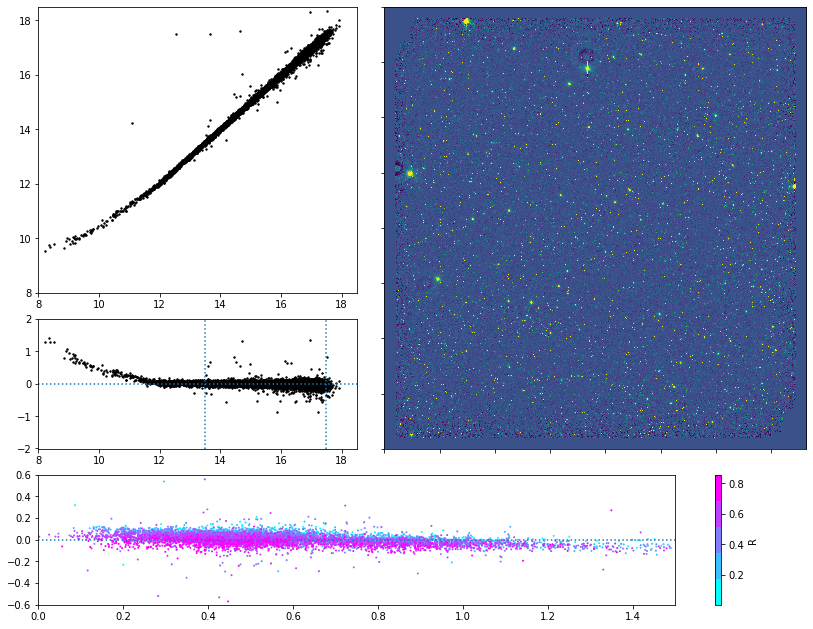

In [3]:
# we plot the magnitudes from the photometry table
ref_band = np.array(zp_cal.df['ref_band'])
ref_sideband = np.array(zp_cal.df['ref_sideband'])
ocam_band = np.array(zp_cal.df['std_mags'])

# we paint with the distance to the center
xdeg = np.array(zp_cal.df['ra'])
ydeg = np.array(zp_cal.df['dec'])
rad_dist = np.sqrt((xdeg -zp_cal.crval1)**2 + (ydeg -zp_cal.crval2)**2)
rad_dist_cmap = cm.get_cmap('cool', 5)

data = zp_cal.data
wcs = zp_cal.wcs

sigma = zp_cal.sigma
mag_max = zp_cal.mag_max
mag_min = zp_cal.mag_min

# we plot the ocam vs skymapper relation
# figsize=(8, 4)
fig = plt.figure(figsize=(14.26, 11.0))

gs = gridspec.GridSpec(nrows=4, ncols=5, wspace=0.0) # width_ratios=[1,1,1,1,1])
ax1 = fig.add_subplot(gs[:-2,:-3])
ax2 = fig.add_subplot(gs[-2, :-3], sharex=ax1)
ax3 = fig.add_subplot(gs[:-1,  -3:])
ax4 = fig.add_subplot(gs[-1,:])


#plt.figure(figsize = (10,10))
#ax1.set_aspect('equal')
ax1.scatter(ref_band, ocam_band,  color='black', s=2)
ax1.set_xlim(8.0, mag_max+1.0)
ax1.set_ylim(8.0, mag_max+1.0)

# delta zp vs mag
ax2.scatter(ref_band, ocam_band - ref_band,  color='black', s=2)
ax2.set_ylim(-10.0*sigma, 10.0*sigma)
ax2.axhline(0.0, ls=':')
ax2.axvline(mag_min, ls=':')
ax2.axvline(mag_max, ls=':')

# and we plot apertures on image
  
norm = simple_norm(data, 'sqrt', percent=99)
ax3.imshow(data, norm=norm)
zp_cal.aperture.to_pixel(wcs).plot(color='white', lw=1)

plt.setp(ax3.get_xticklabels(), visible=False)
plt.setp(ax3.get_yticklabels(), visible=False)

# delta zp vs color
color = ref_sideband - ref_band
select = (13.0 < ref_band) & (ref_band < 16.5)

# the slope of 0.994 gives a bias at fainter magnitudes
# that translate into an offset. If we set slope to 1
# for this plot we get an offset 0.1 mags.
#
plot4 = ax4.scatter(color[select], ocam_band[select] - ref_band[select],  c=rad_dist[select], cmap=rad_dist_cmap, s=1)
p4 = plt.colorbar(plot4, ax=ax4, label='R')
ax4.set_ylim(-0.60, 0.60)
ax4.set_xlim(-0.0, 1.5)
ax4.axhline(0.0, ls=':')
# plt.setp([ax1, ax2, ax3, ax4], title='ZP Conversion')

figname=reduced_dir+'mefpp_zp_skymapper_calibration_check.png'
plt.savefig(figname)
plt.show()


In [4]:
# here we close the loop doing the aperture photometry
# in the fits file produced before.
#

# we read the image
filename = reduced_dir+'test.fits'
cal_data, cal_hdu = fits.getdata(filename, header=True)
cal_wcs = WCS(filename)

# we read the needed keywords for the photometry
zkeys = ['MAGZP', 'HIERARCH MEFPP QC PHO RAD', 'HIERARCH MEFPP QC PHO SKYR1', 'HIERARCH MEFPP QC PHO SKYR2']
cal_key_dict = getKeyListVal(filename, zkeys)
cal_magzp = cal_key_dict['MAGZP']
cal_pho_r = cal_key_dict['HIERARCH MEFPP QC PHO RAD']
cal_pho_sr1 = cal_key_dict['HIERARCH MEFPP QC PHO SKYR1']
cal_pho_sr2 = cal_key_dict['HIERARCH MEFPP QC PHO SKYR2']
print(cal_magzp, cal_pho_r, cal_pho_sr1, cal_pho_sr2)

# we read the photometry table mefpp_zp_skymapper_phot.tsv
#
phot_filename = reduced_dir+'mefpp_zp_skymapper_phot.tsv'
cal_df = pd.read_csv(phot_filename, sep='\t')
cal_df
cal_ra =  np.array(cal_df['ra'])*u.deg
cal_dec = np.array(cal_df['dec'])*u.deg
x = np.array(cal_df['ref_band'])
xg = np.array(cal_df['ref_sideband'])

# this is to check the table. Comment it out when closing the loop
#y = np.array(cal_df['std_mags'])

# Define positions and apertures
logging.info('creating aperture object')
cal_positions = SkyCoord(ra=cal_ra, dec=cal_dec,frame='icrs')
cal_aperture = SkyCircularAperture(cal_positions, r=cal_pho_r * u.arcsec)
cal_sky_annulus = SkyCircularAnnulus(cal_positions, cal_pho_sr1*u.arcsec, cal_pho_sr2*u.arcsec)
            
# here we do the aperture photometry in the calibrated FITS frame            
logging.info('doing aperture photometry on frame.')
cal_phot_table = aperture_photometry(cal_data, [cal_aperture, cal_sky_annulus], wcs=cal_wcs)
for col in cal_phot_table.colnames:
    if 'aperture_sum' in col:
        cal_phot_table[col].info.format = '%.8g'  # for consistent table output

phot_disk_area = cal_aperture.to_pixel(cal_wcs).area
phot_sky_area = cal_sky_annulus.to_pixel(cal_wcs).area

y = -2.5*np.log10(np.array(cal_phot_table['aperture_sum_0'])) + cal_magzp




2020-05-15 17:00:49,600:WARNING:FITSFixedWarning: 'datfix' made the change 'Set DATE-OBS to '2017-03-13T23:17:13.519' from MJD-OBS'.
2020-05-15 17:00:49,632:INFO:creating aperture object
2020-05-15 17:00:49,635:INFO:doing aperture photometry on frame.


27.31875239444676 2.0 4.0 7.0


/opt/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:48: RuntimeWarning: divide by zero encountered in log10


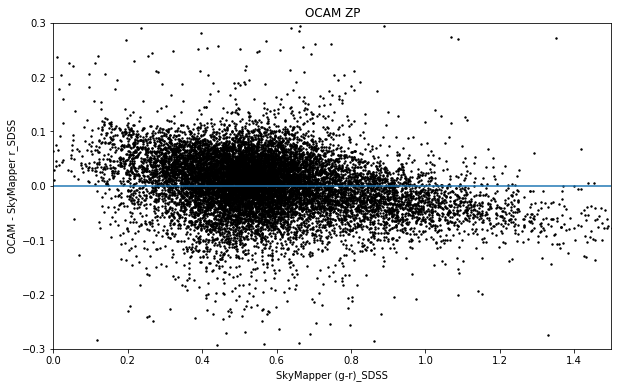

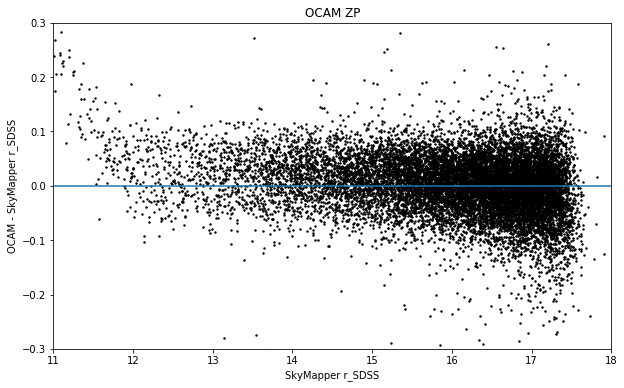

In [5]:
# Plot zeropoint versus color
plt.figure(figsize = (10,6))
plt.xlim(0.0, 1.5)
plt.ylim(-0.3, 0.3)
plt.scatter(xg - x, y - x,  color='black', s=2)
plt.title('OCAM ZP')
plt.xlabel('SkyMapper (g-r)_SDSS')
plt.ylabel('OCAM - SkyMapper r_SDSS')
plt.axhline(y=0.0)
#plt.xticks(())
#plt.yticks(())

#plt.plot(X1, Y1 - (model[0]*X1+model[1]), color='red',linewidth=2)
plt.savefig(reduced_dir+'mefpp_zp_skymapper_sanity_delta_color.png')
plt.show()

# Plot zeropoint versus magnitude
plt.figure(figsize = (10,6))
plt.xlim(11, 18.0)
plt.ylim(-0.3, 0.3) 
plt.scatter(x, y - x,  color='black', s=2)
plt.title('OCAM ZP')
plt.xlabel('SkyMapper r_SDSS')
plt.ylabel('OCAM - SkyMapper r_SDSS')
plt.axhline(y=0.0)
#plt.xticks(())
#plt.yticks(())

plt.savefig(reduced_dir+'mefpp_zp_skymapper_sanity_delta_mag.png')
plt.show()